# 6. Differential equations

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/sympy-for-engineers/blob/main/notebooks/06_differential_equations.ipynb)

Balances of mass, momentum and energy produce differential equations. `sp.dsolve` solves the
ones that have closed-form solutions, which covers most of what appears in undergraduate courses.

The recipe is always the same:

1. declare the unknown as a `Function`
2. write the equation with `.diff`
3. call `dsolve`, passing initial or boundary conditions with `ics=`
4. check the answer with `checkodesol`

**Worked examples:** cooling of a hot object, a damped oscillator, laminar pipe flow of Newtonian
and power-law fluids, a cooling fin, and reactions in series.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

sp.init_printing(use_latex="mathjax")
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2, "figure.figsize": (6.4, 4),
})

## 6.1 First order: Newton's law of cooling

**Problem.** An object at temperature $T_0$ is placed in surroundings at $T_a$. Its temperature
obeys $\dfrac{dT}{dt} = -k\,(T - T_a)$.

In [2]:
t = sp.symbols("t", nonnegative=True)
k, T_a, T_0 = sp.symbols("k T_a T_0", positive=True)
T = sp.Function("T")

cooling = sp.Eq(T(t).diff(t), -k * (T(t) - T_a))
sp.dsolve(cooling, T(t))                      # general solution, with one constant C1

           -k⋅t     
T(t) = C₁⋅ℯ     + Tₐ

In [3]:
T_sol = sp.dsolve(cooling, T(t), ics={T(0): T_0})
T_sol

                       -k⋅t
T(t) = Tₐ + (T₀ - Tₐ)⋅ℯ    

In [4]:
# verify: satisfies the equation, the initial condition, and the long-time limit
assert sp.checkodesol(cooling, T_sol)[0]
assert T_sol.rhs.subs(t, 0) == T_0 and sp.limit(T_sol.rhs, t, sp.oo) == T_a

## 6.2 Second order: the damped oscillator

**Problem.** A mass–spring–damper, an RLC circuit and a U-tube manometer all obey

$$\ddot x + 2\zeta\omega_n \dot x + \omega_n^2 x = 0 .$$

The general solution shows why the damping ratio $\zeta = 1$ is special:

In [5]:
zeta, omega_n = sp.symbols("zeta omega_n", positive=True)
x = sp.Function("x")

oscillator = x(t).diff(t, 2) + 2 * zeta * omega_n * x(t).diff(t) + omega_n**2 * x(t)
sp.dsolve(oscillator, x(t))

                ⎛       _______   _______⎞             ⎛      _______   _______⎞
           ωₙ⋅t⋅⎝-ζ + ╲╱ ζ - 1 ⋅╲╱ ζ + 1 ⎠       -ωₙ⋅t⋅⎝ζ + ╲╱ ζ - 1 ⋅╲╱ ζ + 1 ⎠
x(t) = C₁⋅ℯ                                + C₂⋅ℯ                               

The exponents contain $\sqrt{\zeta - 1}$: real for $\zeta > 1$ (two decaying exponentials),
imaginary for $\zeta < 1$ (oscillation). Fix $\omega_n = 1$, release from rest at $x = 1$, and
compare three damping ratios. Entering $\zeta$ as an exact number gives a clean result.

In [6]:
release = {x(0): 1, x(t).diff(t).subs(t, 0): 0}
cases = {"underdamped, ζ = 0.2": sp.Rational(1, 5), "critically damped, ζ = 1": 1, "overdamped, ζ = 2": 2}

responses = {}
for label, z in cases.items():
    ode = oscillator.subs({zeta: z, omega_n: 1})
    solution = sp.dsolve(ode, x(t), ics=release)
    assert sp.checkodesol(ode, solution)[0]
    responses[label] = solution.rhs
    display(solution)

       ⎛      ⎛2⋅√6⋅t⎞              ⎞  -t 
       ⎜√6⋅sin⎜──────⎟              ⎟  ───
       ⎜      ⎝  5   ⎠      ⎛2⋅√6⋅t⎞⎟   5 
x(t) = ⎜────────────── + cos⎜──────⎟⎟⋅ℯ   
       ⎝      12            ⎝  5   ⎠⎠     

                -t
x(t) = (t + 1)⋅ℯ  

       ⎛1   √3⎞  t⋅(-2 + √3)   ⎛1   √3⎞  -t⋅(√3 + 2)
x(t) = ⎜─ + ──⎟⋅ℯ            + ⎜─ - ──⎟⋅ℯ           
       ⎝2   3 ⎠                ⎝2   3 ⎠             

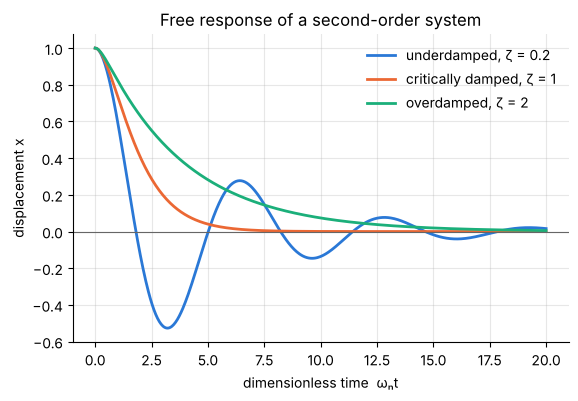

In [7]:
ts = np.linspace(0, 20, 500)
fig, ax = plt.subplots()
for label, response in responses.items():
    ax.plot(ts, sp.lambdify(t, response, "numpy")(ts), label=label)
ax.axhline(0, color="0.4", lw=0.8)
ax.set(xlabel="dimensionless time  ωₙt", ylabel="displacement x", title="Free response of a second-order system")
ax.legend(frameon=False);

## 6.3 A boundary value problem: laminar flow in a pipe

**Problem.** Fully developed laminar flow of a Newtonian fluid in a pipe of radius $R$, driven by
a pressure gradient $G = -dP/dz$. Find the velocity profile and the flow rate.

**By hand.** The axial momentum balance is
$\dfrac{\mu}{r}\dfrac{d}{dr}\!\left(r\dfrac{du}{dr}\right) = -G$, with $u(R) = 0$ (no slip) and
$u$ finite on the axis.

In [8]:
r, R, mu, G = sp.symbols("r R mu G", positive=True)
u = sp.Function("u")

momentum = sp.Eq(mu / r * sp.Derivative(r * u(r).diff(r), r), -G)
general = sp.dsolve(momentum, u(r))
general

                           2
                        G⋅r 
u(r) = C₁ + C₂⋅log(r) - ────
                        4⋅μ 

"Finite at $r = 0$" is not a condition `dsolve` accepts, so impose it yourself: the $\ln r$ term
must vanish. Then apply no slip at the wall.

In [9]:
C1, C2 = sp.symbols("C1 C2")
assert general.rhs.coeff(sp.log(r)) == C2

bounded = general.rhs.subs(C2, 0)
u_pipe = sp.factor(bounded.subs(C1, sp.solve(bounded.subs(r, R), C1)[0]))
u_pipe

-G⋅(-R + r)⋅(R + r) 
────────────────────
        4⋅μ         

In [10]:
Q = sp.integrate(2 * sp.pi * r * u_pipe, (r, 0, R))
u_mean = sp.simplify(Q / (sp.pi * R**2))
Q, sp.simplify(u_pipe.subs(r, 0) / u_mean)

⎛     4   ⎞
⎜π⋅G⋅R    ⎟
⎜──────, 2⎟
⎝ 8⋅μ     ⎠

This is the Hagen–Poiseuille law, $Q = \pi G R^4 / (8\mu)$, and the centreline velocity is twice
the mean. **Verify** both.

In [11]:
assert sp.simplify(Q - sp.pi * G * R**4 / (8 * mu)) == 0
assert sp.simplify(u_pipe.subs(r, 0) / u_mean) == 2

### The same pipe with a power-law fluid

Polymer solutions, paints and many food products are not Newtonian. In the power-law model the
shear stress is $\tau = K\,\dot\gamma^{\,n}$ ($n < 1$ shear-thinning, $n > 1$ shear-thickening).
A force balance on a fluid cylinder gives $\tau = G r / 2$ for any fluid, so

$$-\frac{du}{dr} = \left(\frac{G\,r}{2K}\right)^{1/n}.$$

This is a direct integration.

In [12]:
n, K = sp.symbols("n K", positive=True)

u_indef = sp.integrate(-(G * r / (2 * K)) ** (1 / n), r)
u_power = sp.simplify(u_indef - u_indef.subs(r, R))                    # no slip at r = R
Q_power = sp.simplify(sp.integrate(2 * sp.pi * r * u_power, (r, 0, R)))
u_power, Q_power

⎛            ⎛     1        1⎞     3⋅n + 1            ⎞
⎜      _____ ⎜ 1 + ─    1 + ─⎟     ───────       _____⎟
⎜     ╱  G   ⎜     n        n⎟        n         ╱  G  ⎟
⎜n⋅n ╱  ─── ⋅⎝R      - r     ⎠  π⋅R       ⋅n⋅n ╱  ─── ⎟
⎜  ╲╱   2⋅K                                  ╲╱   2⋅K ⎟
⎜─────────────────────────────, ──────────────────────⎟
⎝            n + 1                     3⋅n + 1        ⎠

In [13]:
# verify: n = 1 and K = mu must recover the Newtonian results
assert sp.simplify(Q_power.subs({n: 1, K: mu}) - Q) == 0
assert sp.simplify(u_power.subs({n: 1, K: mu}) - u_pipe) == 0

profile = sp.simplify(u_power / (Q_power / (sp.pi * R**2)))            # u / u_mean
profile

 -(n + 1)  ⎛ n + 1    n + 1⎞          
 ───────── ⎜ ─────    ─────⎟          
     n     ⎜   n        n  ⎟          
R         ⋅⎝R      - r     ⎠⋅(3⋅n + 1)
──────────────────────────────────────
                n + 1                 

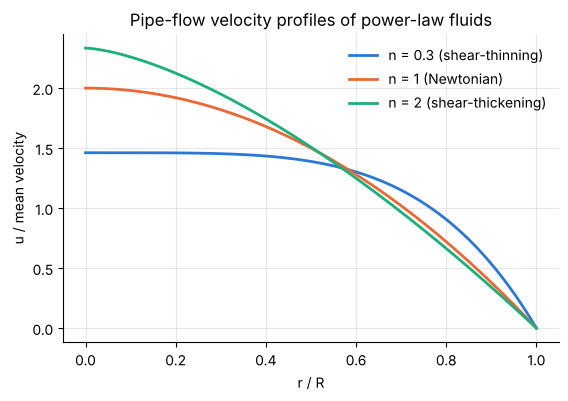

In [14]:
rs = np.linspace(0, 1, 200)
fig, ax = plt.subplots()
for index, name in ((0.3, "n = 0.3 (shear-thinning)"), (1, "n = 1 (Newtonian)"), (2, "n = 2 (shear-thickening)")):
    ax.plot(rs, sp.lambdify(r, profile.subs({n: index, R: 1}), "numpy")(rs), label=name)
ax.set(xlabel="r / R", ylabel="u / mean velocity", title="Pipe-flow velocity profiles of power-law fluids")
ax.legend(frameon=False);

Shear-thinning fluids flow almost as a plug: the centreline velocity is
$\dfrac{3n+1}{n+1}$ times the mean, which falls from 2 towards 1 as $n \to 0$.

## 6.4 Conditions at two different points: a cooling fin

**Problem.** A straight fin of length $L$ has excess temperature $\theta = T - T_\infty$ obeying
$\theta'' = m^2\theta$, with $\theta(0) = \theta_b$ at the base and an insulated tip, $\theta'(L) = 0$.

In [15]:
xs, L, m, theta_b = sp.symbols("x L m theta_b", positive=True)
theta = sp.Function("theta")

fin = theta(xs).diff(xs, 2) - m**2 * theta(xs)
fin_sol = sp.dsolve(fin, theta(xs), ics={theta(0): theta_b, theta(xs).diff(xs).subs(xs, L): 0})
sp.simplify(fin_sol.rhs)

    ⎛ 2⋅L⋅m    2⋅m⋅x⎞  -m⋅x
θ_b⋅⎝ℯ      + ℯ     ⎠⋅ℯ    
───────────────────────────
         2⋅L⋅m             
        ℯ      + 1         

SymPy answers in exponentials. Textbooks write the same function as
$\theta_b\,\dfrac{\cosh m(L-x)}{\cosh mL}$. To confirm two expressions are equal, simplify their
difference to zero:

In [16]:
textbook = theta_b * sp.cosh(m * (L - xs)) / sp.cosh(m * L)
assert sp.simplify((fin_sol.rhs - textbook).rewrite(sp.exp)) == 0

In [17]:
# heat flow into the fin, relative to an ideal fin entirely at the base temperature
heat_ratio = sp.simplify((-textbook.diff(xs).subs(xs, 0) / (m**2 * L * theta_b)))
assert sp.simplify(heat_ratio - sp.tanh(m * L) / (m * L)) == 0
heat_ratio

tanh(L⋅m)
─────────
   L⋅m   

That is the fin efficiency $\tanh(mL)/(mL)$ whose limits were examined in notebook 3.

## 6.5 Systems of equations: reactions in series

**Problem.** $A \xrightarrow{k_1} B \xrightarrow{k_2} C$ in a batch reactor, starting with pure $A$.
When is the concentration of the intermediate $B$ highest?

In [18]:
A, B, C = (sp.Function(name) for name in "ABC")
k1, k2, A0 = sp.symbols("k_1 k_2 A_0", positive=True)

kinetics = [
    sp.Eq(A(t).diff(t), -k1 * A(t)),
    sp.Eq(B(t).diff(t), k1 * A(t) - k2 * B(t)),
    sp.Eq(C(t).diff(t), k2 * B(t)),
]
series = sp.dsolve(kinetics, [A(t), B(t), C(t)], ics={A(0): A0, B(0): 0, C(0): 0})
series

⎡                                -k₂⋅t          -k₁⋅t                  -k₂⋅t   ↪
⎢           -k₁⋅t         A₀⋅k₁⋅ℯ        A₀⋅k₁⋅ℯ                A₀⋅k₁⋅ℯ        ↪
⎢A(t) = A₀⋅ℯ     , B(t) = ──────────── - ────────────, C(t) = - ──────────── + ↪
⎣                           k₁ - k₂        k₁ - k₂                k₁ - k₂      ↪

↪         -k₁⋅t     ⎤
↪  A₀⋅k₂⋅ℯ          ⎥
↪  ──────────── + A₀⎥
↪    k₁ - k₂        ⎦

In [19]:
A_t, B_t, C_t = (eq.rhs for eq in series)
assert sp.simplify(A_t + B_t + C_t - A0) == 0          # verify: total moles are conserved

t_max = sp.solve(sp.diff(B_t, t), t)[0]
t_max

    ⎛k₂⎞ 
-log⎜──⎟ 
    ⎝k₁⎠ 
─────────
 k₁ - k₂ 

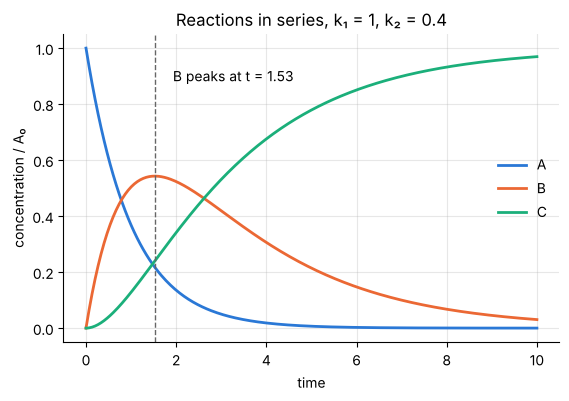

In [20]:
rates = {k1: 1.0, k2: 0.4, A0: 1.0}
ts = np.linspace(0, 10, 300)
fig, ax = plt.subplots()
for species, name in ((A_t, "A"), (B_t, "B"), (C_t, "C")):
    ax.plot(ts, sp.lambdify(t, species.subs(rates), "numpy")(ts), label=name)
t_star = float(t_max.subs(rates))
ax.axvline(t_star, color="0.4", lw=1, ls="--")
ax.annotate(f"B peaks at t = {t_star:.2f}", xy=(t_star, 0.9), xytext=(t_star + 0.4, 0.9), va="center")
ax.set(xlabel="time", ylabel="concentration / A₀", title="Reactions in series, k₁ = 1, k₂ = 0.4")
ax.legend(frameon=False, loc="center right");

Stopping the reactor at $t^* = \dfrac{\ln(k_1/k_2)}{k_1 - k_2}$ gives the best yield of $B$.

## 6.6 When `dsolve` is not enough

Most nonlinear equations have no closed-form solution, and `dsolve` will either raise
`NotImplementedError` or run for a long time. That is the normal situation in engineering, not a
failure. Notebook 8 shows how to hand a symbolic model to a numerical solver, and notebook 13
covers how to recognise these cases early.

Sometimes a different idea rescues an exact solution. Notebook 16 returns to the pipe of 6.3
with a realistic polymer model, for which the method used here fails, and finds an almost
closed-form answer by changing the independent variable.

## Exercises

1. A tank of volume $V$ holds brine of concentration $c_0$. Fresh water enters at flow rate $q$
   and the mixture leaves at the same rate. Solve $V\,\dot c = -q c$ and find the time for the
   concentration to fall to 1 % of its initial value.
2. Solve the forced oscillator $\ddot x + 2\zeta\dot x + x = \cos(\Omega t)$ for $\zeta = 1/10$
   and plot the steady-state amplitude against $\Omega$. Where is the resonance peak?
3. Repeat 6.3 for flow between two parallel plates a distance $2h$ apart. The mean velocity
   should be two thirds of the maximum.
4. Change the fin tip condition to a fixed temperature $\theta(L) = 0$ and compare the heat flow.
5. In 6.5, find the maximum concentration of $B$ as a function of $k_2/k_1$ only.